### Name - Astha Madekar
### C-C4-58
### ML-LAB-4

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("WineQT.csv")

In [ ]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [ ]:
df.tail()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,1592
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6,1593
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,1594
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,1595
1142,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5,1597


In [ ]:
df.shape

(1143, 13)

In [ ]:
df.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


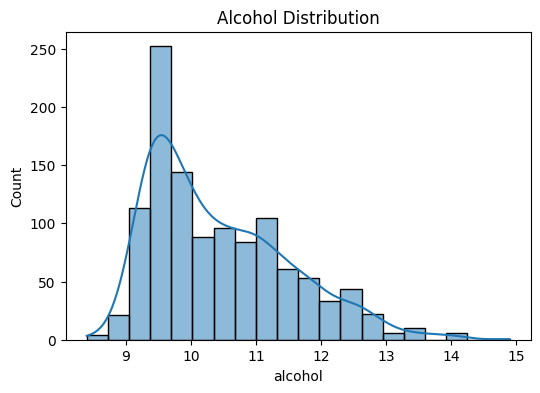

In [ ]:
# Univariate Analysis
plt.figure(figsize=(6,4))
sns.histplot(df["alcohol"], bins=20, kde=True)
plt.title("Alcohol Distribution")
plt.show()

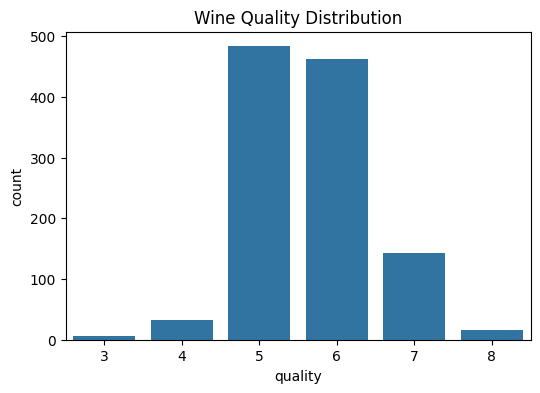

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x=df["quality"])
plt.title("Wine Quality Distribution")
plt.show()

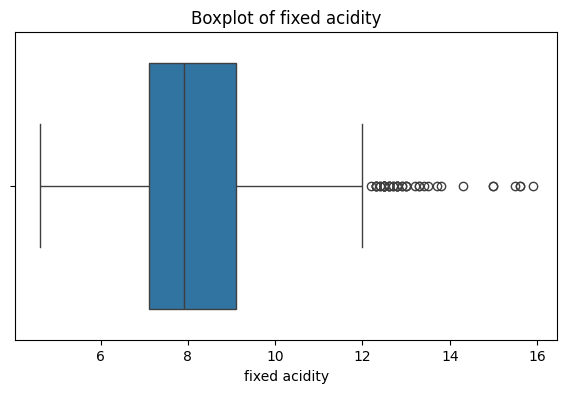

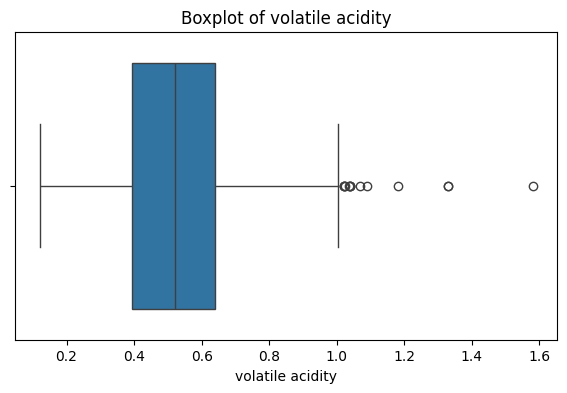

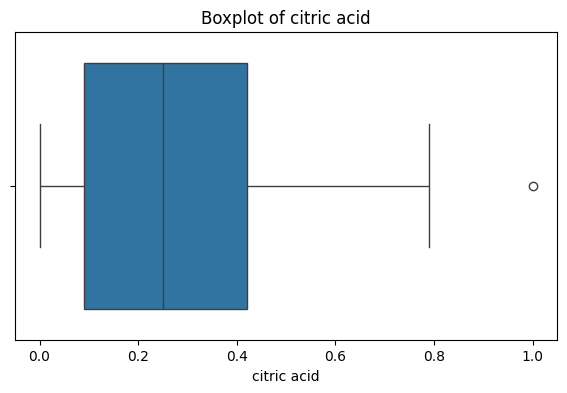

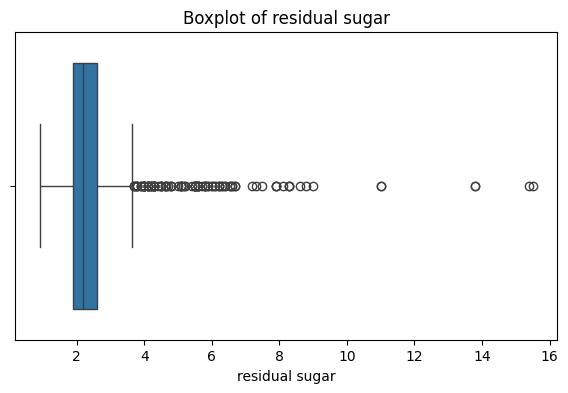

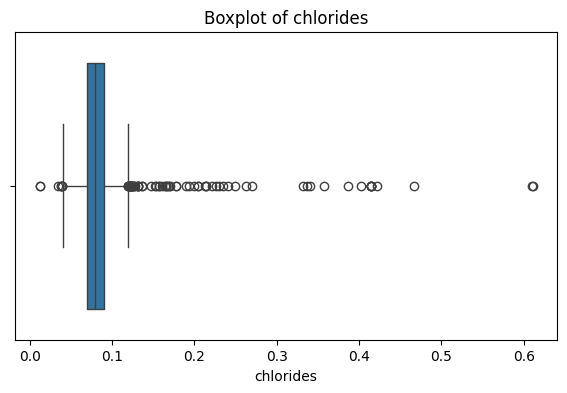

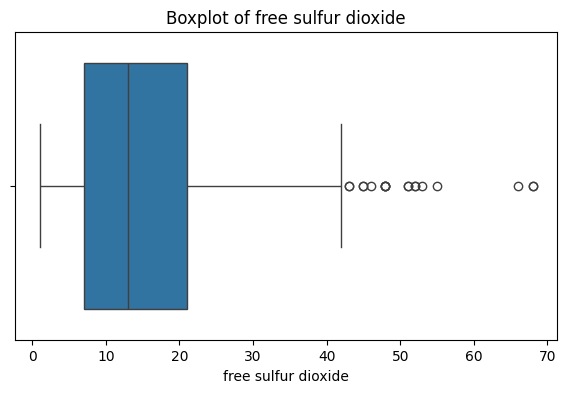

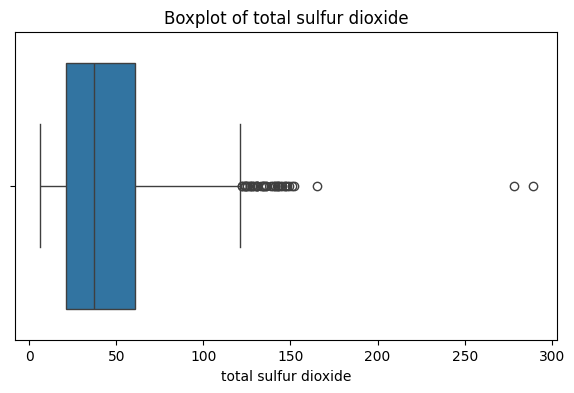

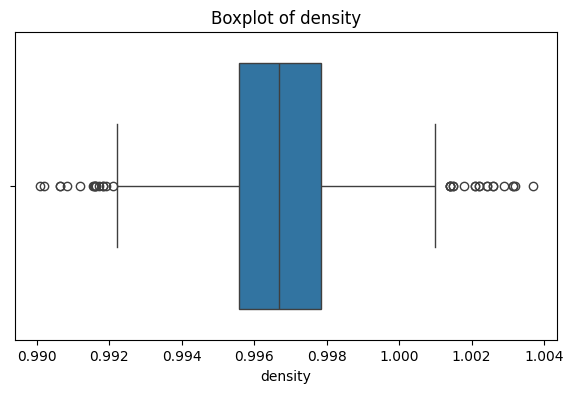

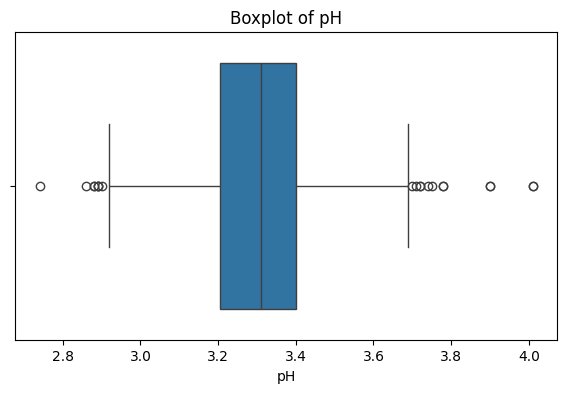

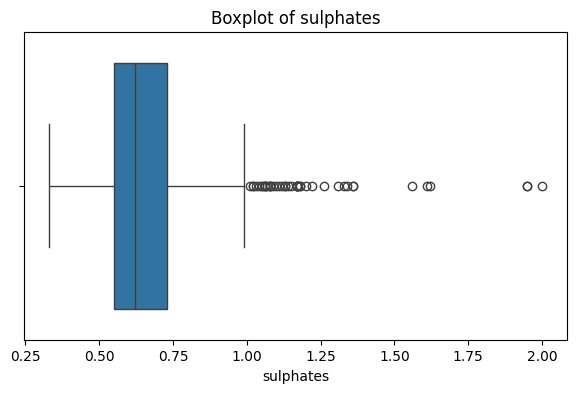

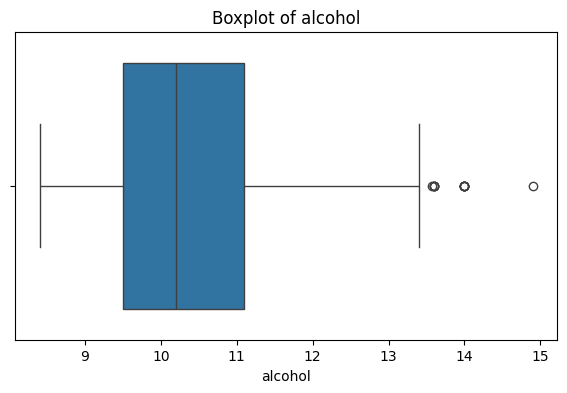

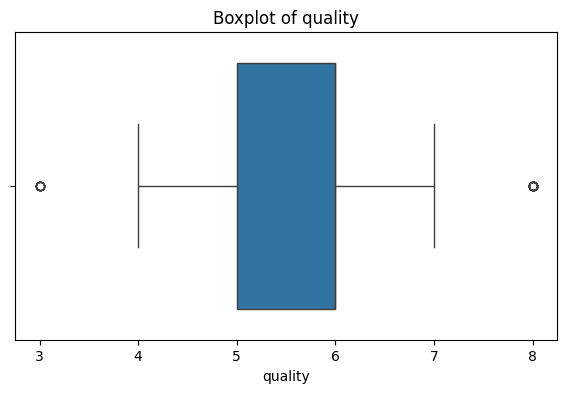

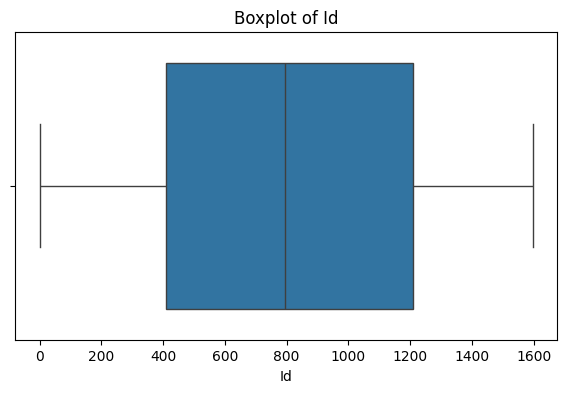

In [ ]:
numeric_cols = df.select_dtypes(include='number').columns
for col in numeric_cols:
    plt.figure(figsize=(7,4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [ ]:
# Remove target column
features = df.drop(columns=['quality'])
Q1 = features.quantile(0.25)
Q3 = features.quantile(0.75)
# Calculate IQR
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers_mask = features[(features < lower_bound) | (features > upper_bound)]
outlier_count = outliers_mask.sum()
outlier_percentage = (outlier_count / len(features)) * 100
outlier_summary = pd.DataFrame({
    'Q1': Q1,
    'Q3': Q3,
    'IQR': IQR,
    'Lower Bound': lower_bound,
    'Upper Bound': upper_bound,
    'Outlier Count': outlier_count,
    'Outlier Percentage': outlier_percentage
})

outlier_summary.round(3)

,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
fixed acidity,7.100,9.100,2.000,4.100,12.100,579.400,50.691
volatile acidity,0.392,0.640,0.248,0.021,1.011,15.820,1.384
citric acid,0.090,0.420,0.330,-0.405,0.915,1.000,0.087
residual sugar,1.900,2.600,0.700,0.850,3.650,640.400,56.028
chlorides,0.070,0.090,0.020,0.040,0.120,15.466,1.353
free sulfur dioxide,7.000,21.000,14.000,-14.000,42.000,930.000,81.365
total sulfur dioxide,21.000,61.000,40.000,-39.000,121.000,5740.000,502.187
density,0.996,0.998,0.002,0.992,1.001,35.906,3.141
pH,3.205,3.400,0.195,2.913,3.692,68.650,6.006
sulphates,0.550,0.730,0.180,0.280,1.000,52.960,4.633


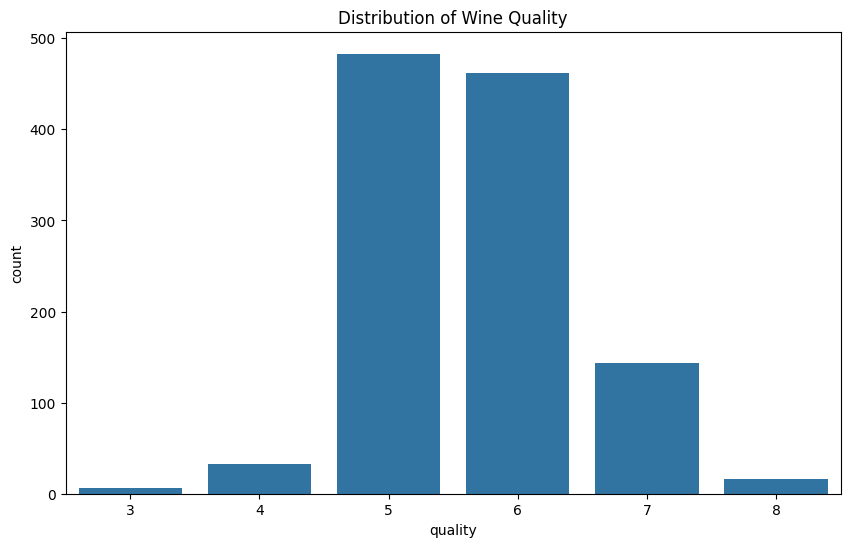

In [ ]:
plt.figure(figsize=(10,6))
sns.countplot(x='quality',data=df)
plt.title('Distribution of Wine Quality')
plt.show()

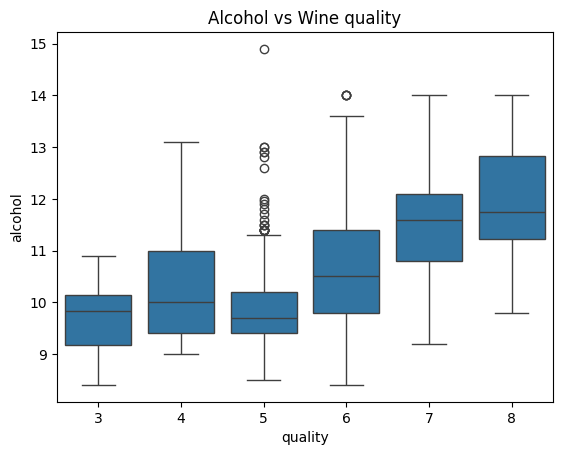

In [ ]:
# Bivariate analysis
sns.boxplot(x='quality',y='alcohol',data=df)
plt.title('Alcohol vs Wine quality')
plt.show()

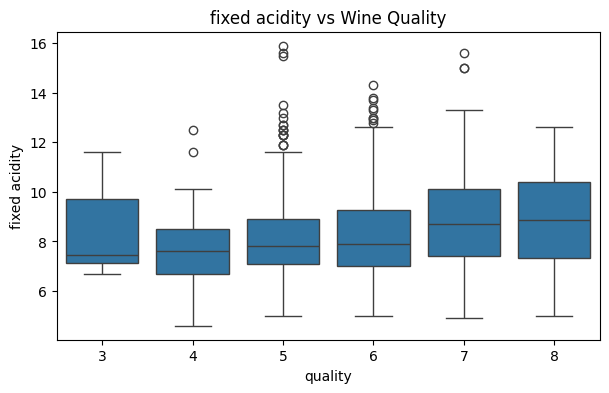

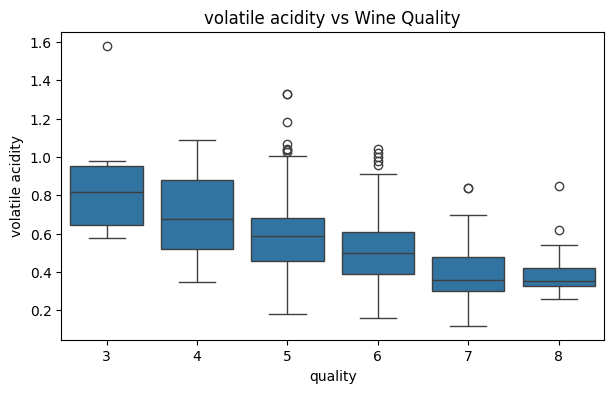

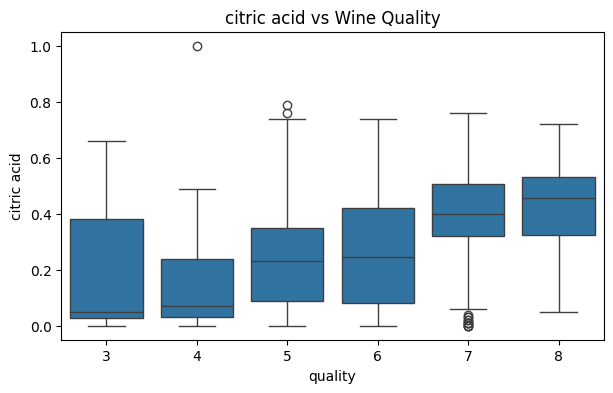

In [ ]:
features = ['fixed acidity', 'volatile acidity', 'citric acid']
for col in features:
    plt.figure(figsize=(7,4))
    sns.boxplot(x='quality', y=col, data=df)
    plt.title(f'{col} vs Wine Quality')
    plt.show()

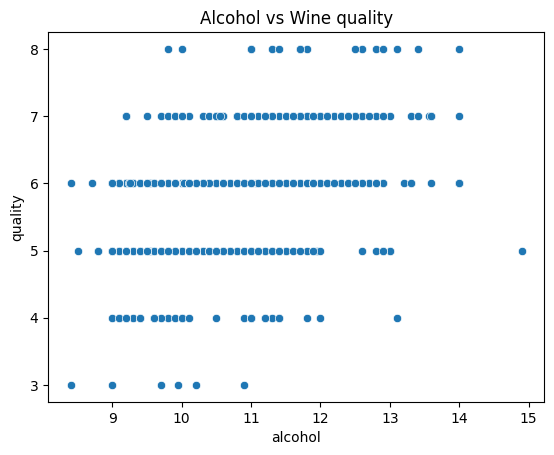

In [ ]:
sns.scatterplot(x='alcohol',y='quality',data=df)
plt.title('Alcohol vs Wine quality')
plt.show()

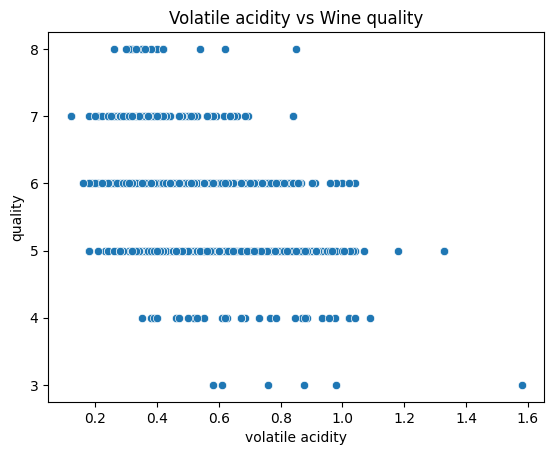

In [ ]:
sns.scatterplot(x='volatile acidity',y='quality',data=df)
plt.title('Volatile acidity vs Wine quality')
plt.show()

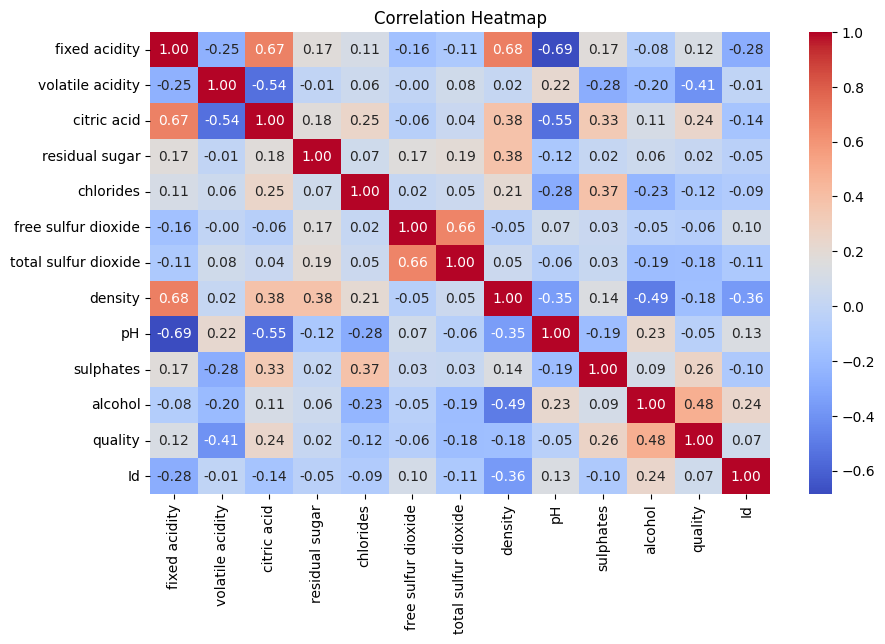

In [ ]:
# Multivariate Analysis
plt.figure(figsize=(10,6))
corr = df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

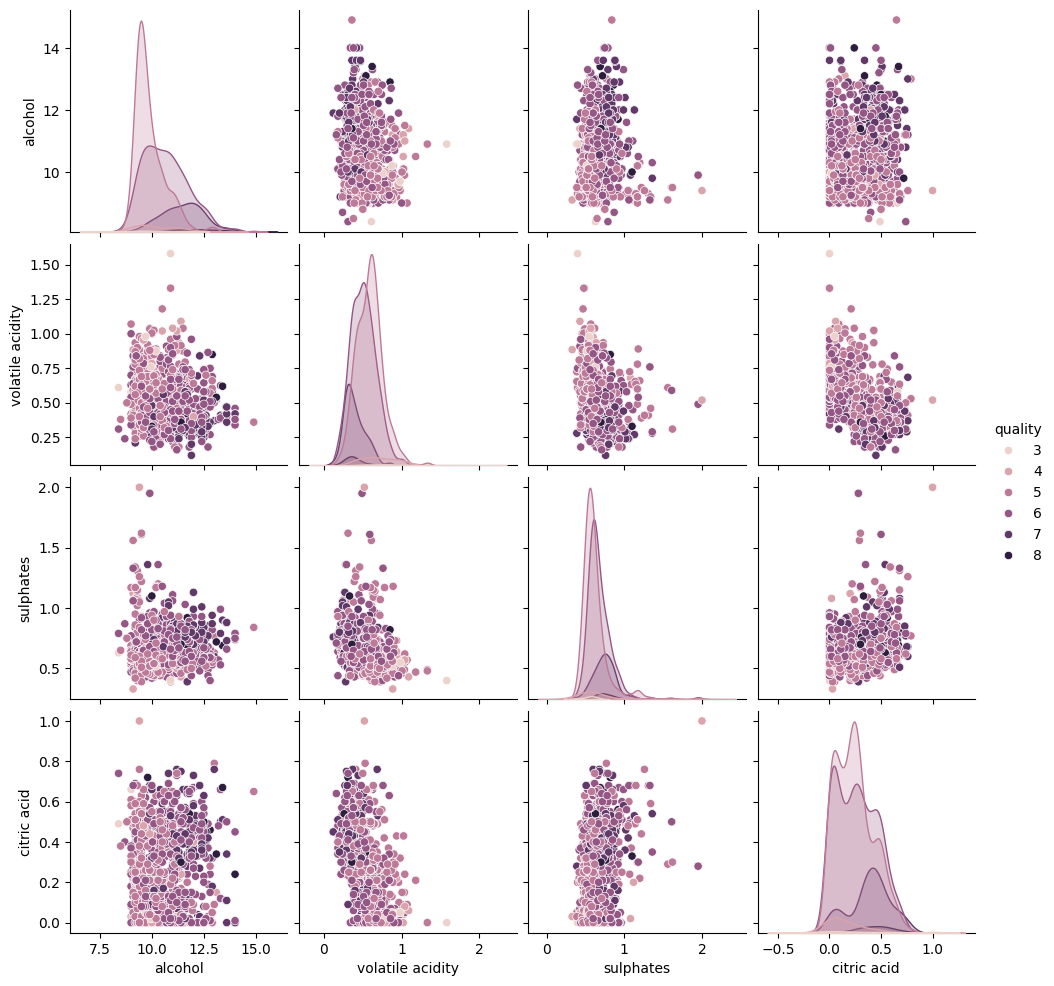

In [ ]:
selected = ['alcohol', 'volatile acidity', 'sulphates', 'citric acid', 'quality']
sns.pairplot(df[selected], hue='quality')
plt.show()

In [ ]:
#multivariate analysis using quality groups
df['quality_group'] = pd.cut(
    df['quality'],
    bins=[0,5,6,10],
    labels=['Low','Medium','High']
    )

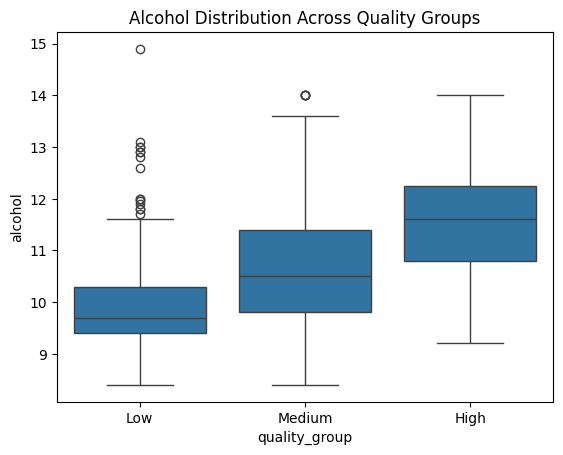

In [ ]:
sns.boxplot(
    x='quality_group',
    y='alcohol',
    data=df
    )
plt.title('Alcohol Distribution Across Quality Groups')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                                f1_score, classification_report , confusion_matrix, ConfusionMatrixDisplay)


In [ ]:
X = df.drop('quality', axis=1)
y = df['quality']

In [ ]:
print(y.value_counts())

quality
5    483
6    462
7    143
4     33
8     16
3      6
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
criterion='entropy'

In [ ]:
dt_model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

In [ ]:
# Convert target labels to numbers
y = df['quality_group'].map({
    'Low': 0,
    'Medium': 1,
    'High': 2
})
X = df.drop(['quality', 'quality_group'], axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

y_train_pred = dt_model.predict(X_train)
y_test_pred = dt_model.predict(X_test)

In [ ]:
train_accuracy = accuracy_score(y_train, y_train_pred)
print("Training Accuracy:", train_accuracy)

Training Accuracy: 1.0


In [ ]:
test_accuracy = accuracy_score(y_test, y_test_pred)
print("Testing Accuracy:", test_accuracy)

Testing Accuracy: 0.5982532751091703


In [ ]:
print("Precision:",
      precision_score(y_test, y_test_pred, average='weighted'))
print("Recall:",
      recall_score(y_test, y_test_pred, average='weighted'))
print("F1 Score:",
      f1_score(y_test, y_test_pred, average='weighted'))
print(classification_report(y_test, y_test_pred))

Precision: 0.6007363644147615
Recall: 0.5982532751091703
F1 Score: 0.5968530472754888
              precision    recall  f1-score   support

           0       0.65      0.69      0.67       102
           1       0.59      0.51      0.54        99
           2       0.47      0.61      0.53        28

    accuracy                           0.60       229
   macro avg       0.57      0.60      0.58       229
weighted avg       0.60      0.60      0.60       229



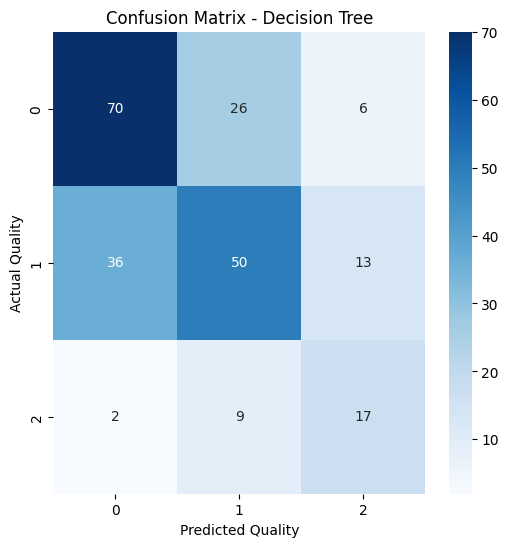

In [ ]:
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Quality')
plt.ylabel('Actual Quality')
plt.title('Confusion Matrix - Decision Tree')

plt.show()

tree depth: 17
number of leaves: 196


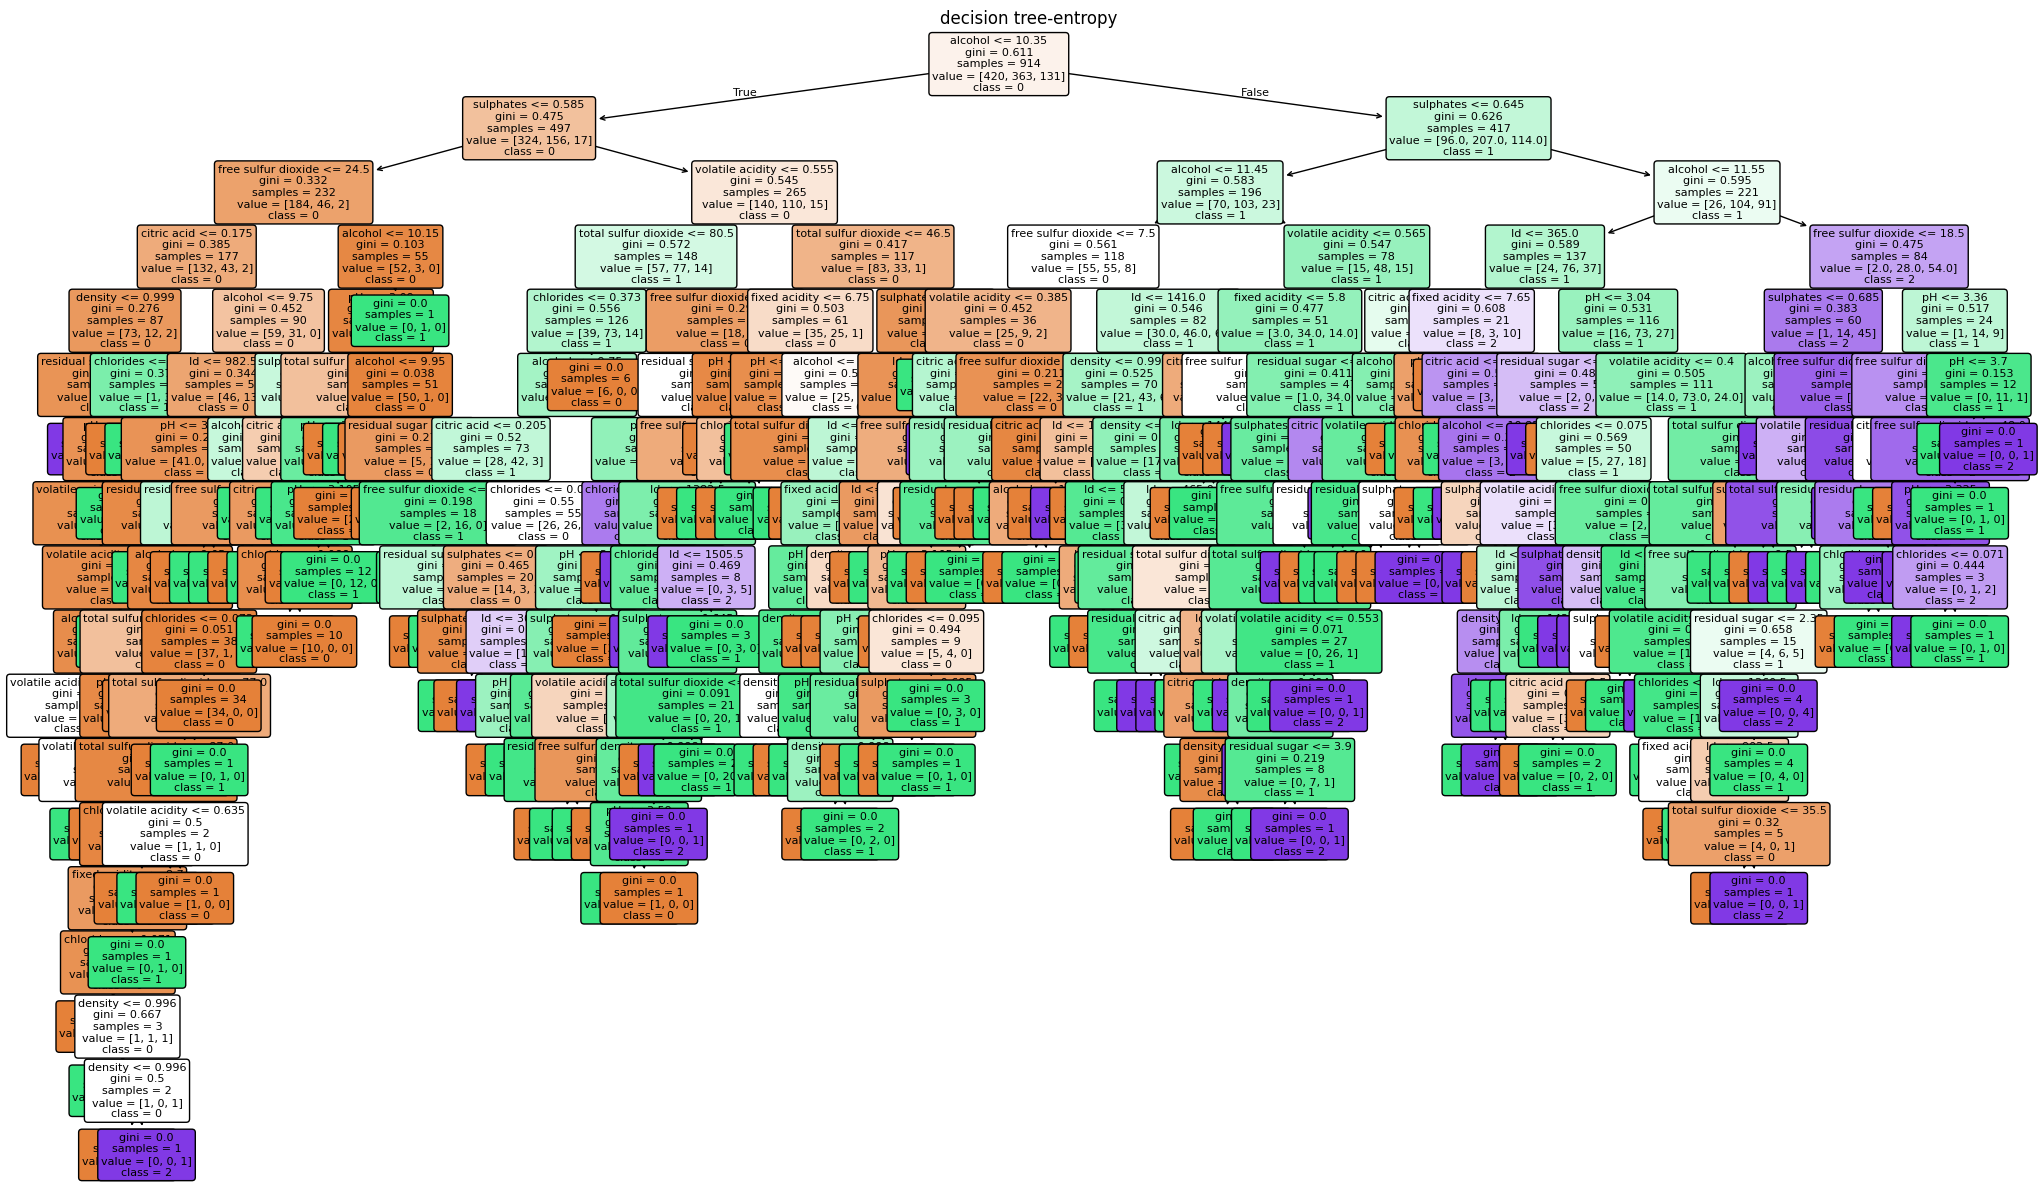

In [ ]:
print("tree depth:", dt_model.get_depth())
print("number of leaves:", dt_model.get_n_leaves())

plt.figure(figsize=(25,15))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=[str(c) for c in sorted(y.unique())],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("decision tree-entropy")
plt.show()

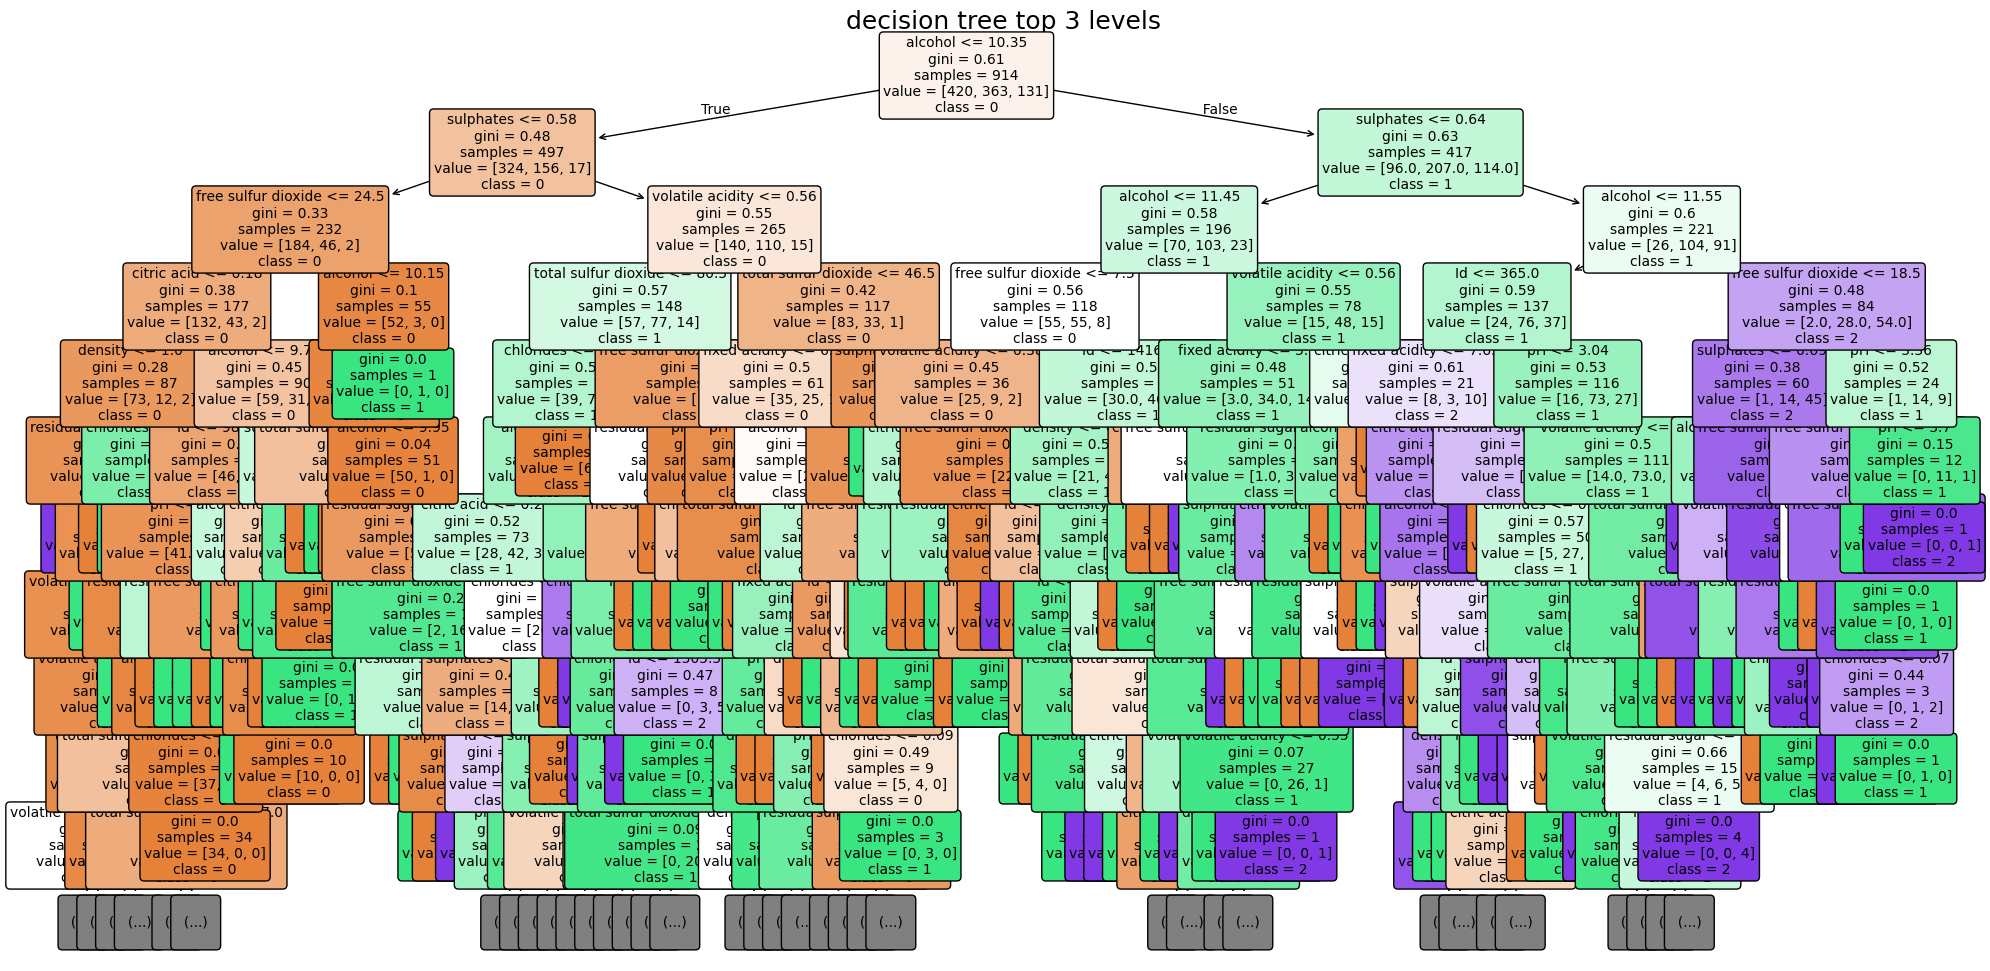

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(24,12))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=[str(c) for c in sorted(y.unique())],
    filled=True,
    rounded=True,
    impurity=True,
    precision=2,
    fontsize=10,
    max_depth=10
)

plt.title("decision tree top 3 levels", fontsize=18)
plt.show()

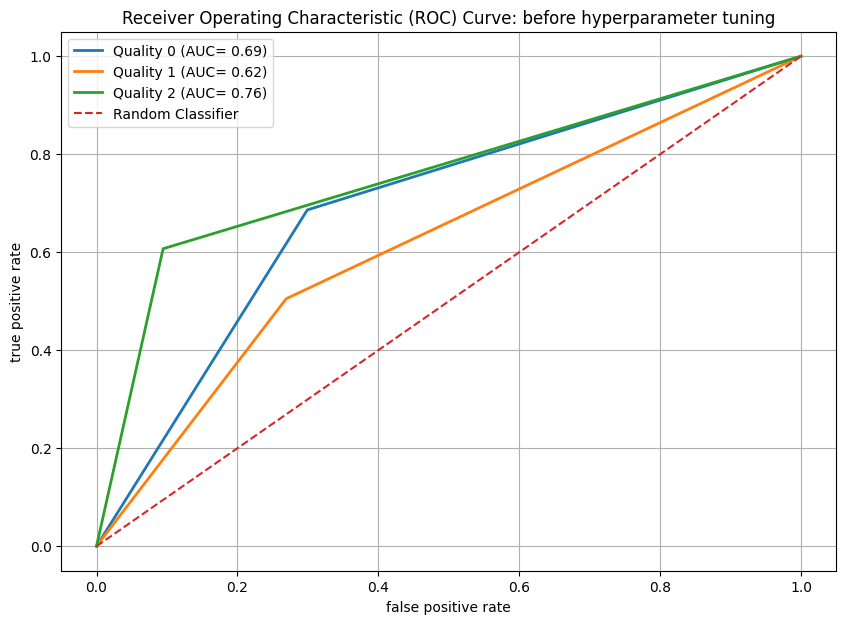

overall auc-roc before tuning 0.6685


In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

classes = sorted(y_test.unique())

y_test_bin = label_binarize(y_test, classes=classes)
y_score = dt_model.predict_proba(X_test)

plt.figure(figsize=(10, 7))

for i, class_label in enumerate(classes):
    fpr, tpr, thresholds = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'Quality {class_label} (AUC= {roc_auc:.2f})'
    )

plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('false positive rate')
plt.ylabel('true positive rate')
plt.title('Receiver Operating Characteristic (ROC) Curve: before hyperparameter tuning')
plt.legend()
plt.grid()
plt.show()

overall_auc_before = roc_auc_score(
    y_test_bin,
    y_score,
    multi_class='ovr',
    average='weighted'
)

print('overall auc-roc before tuning', round(overall_auc_before, 4))

In [ ]:
# Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV
import warnings
warnings.filterwarnings('ignore')

param_grid = {
    'criterion': ['entropy'],
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': [None, 'sqrt', 'log2'],
    'ccp_alpha': [0.001, 0.01, 0.05]
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print('best parameters')
print(grid.best_params_)

print('best cross validation accuracy')
print(grid.best_score_)

best_tree = grid.best_estimator_

best parameters
{'ccp_alpha': 0.001, 'criterion': 'entropy', 'max_depth': None, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 5}
best cross validation accuracy
0.6345643427610641


In [ ]:
# Prediction and Evaluation
y_pred = best_tree.predict(X_test)

print(classification_report(y_test, y_pred))
print("accuracy =", accuracy_score(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.73      0.72      0.72       102
           1       0.62      0.62      0.62        99
           2       0.55      0.61      0.58        28

    accuracy                           0.66       229
   macro avg       0.63      0.65      0.64       229
weighted avg       0.66      0.66      0.66       229

accuracy = 0.6593886462882096


In [ ]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(
    best_tree,
    X,
    y,
    cv=10,
    scoring='accuracy'
)
print(scores)
print("average accuracy=", scores.mean())
print("std=", scores.std())

[0.51304348 0.47826087 0.45217391 0.50877193 0.62280702 0.56140351
 0.52631579 0.5        0.5        0.51754386]
average accuracy= 0.5180320366132722
std= 0.04428060778030475


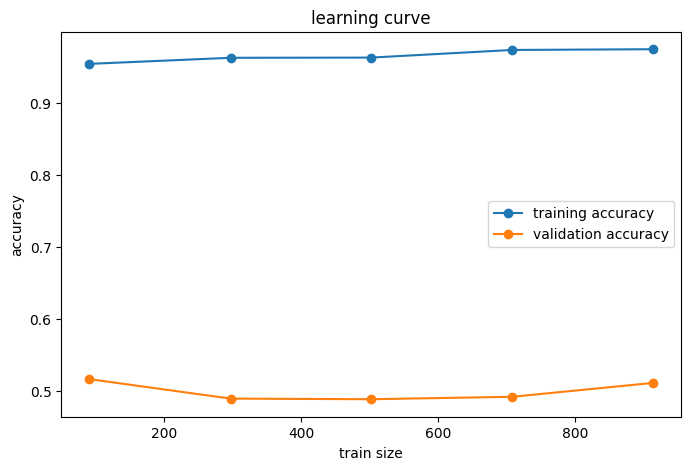

In [ ]:
from sklearn.model_selection import learning_curve
train_sizes, train_scores, test_scores = learning_curve(
    best_tree,
    X, y,cv=5,
    scoring='accuracy'
)

plt.figure(figsize=(8,5))
plt.plot(
    train_sizes,
    train_scores.mean(axis=1),
    marker='o',
    label='training accuracy'
)
plt.plot(
    train_sizes,
    test_scores.mean(axis=1),
    marker='o',
    label='validation accuracy'
)
plt.xlabel("train size")
plt.ylabel("accuracy")
plt.title("learning curve")

plt.legend()
plt.show()

In [ ]:
new_wine = pd.DataFrame([{
    'Id': 1,
    'fixed acidity': 7.4,
    'volatile acidity': 0.7,
    'citric acid': 0.20,
    'residual sugar': 2.0,
    'chlorides': 0.065,
    'free sulfur dioxide': 15.0,
    'total sulfur dioxide': 40.0,
    'density': 1.29,
    'pH': 3.4,
    'sulphates': 0.54,
    'alcohol': 9.4
}])
new_wine = new_wine[best_tree.feature_names_in_]
prediction = best_tree.predict(new_wine)
print("Predicted wine quality:", prediction[0])

Predicted wine quality: 0
